# Mobile-Wallet Fraud Detection (End-to-End Pipeline & App)

## Project Summary
- **Domain:** FinTech · Payments · Imbalanced Binary Classification
- **Dataset:** PaySim Mobile Money Simulation (~6.3M transactions)
- **Target:** `isFraud` (`1` = Fraudulent Transaction, `0` = Legitimate Transaction)
- **Pipeline Included in This Notebook:**
  1. **Memory-Optimized Data Ingestion & EDA** (handling 6.3M rows smoothly).
  2. **Leakage-Free Feature Engineering** (only information available *before* the transaction is approved).
  3. **Sampling & Class Imbalance Strategies** (Class-Weighted LightGBM, Random Undersampling + Random Forest, Unweighted LightGBM).
  4. **Precision-Recall Evaluation (`PR-AUC`)** with a bootstrap confidence interval and a leakage ablation.
  5. **Stretch Goal: Cost Matrix & Robust Threshold Optimization** (minimizing total financial loss from Missed Fraud vs. Blocked Honest Users).
  6. **Interactive App Generation (`app.py`)** (Transaction Form + CSV Upload + Live Threshold & Cost Slider).


In [3]:
# 1. Imports & Environment Configuration
import os
import gc
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

print("Environment ready.")

Environment ready.


## 2. Load Data with Memory Optimization (~6.3M Rows)
Using explicit `float32` and `int8`/`category` dtypes reduces memory footprint by >60% so the notebook runs fast without RAM crashes.

In [4]:
# Update path if your Kaggle CSV is inside a subfolder
DATA_PATH = 'PS_20174392719_1491204439457_log.csv'

dtypes = {
    'step': 'int32',
    'type': 'category',
    'amount': 'float32',
    'nameOrig': 'object',
    'oldbalanceOrg': 'float32',
    'newbalanceOrig': 'float32',
    'nameDest': 'object',
    'oldbalanceDest': 'float32',
    'newbalanceDest': 'float32',
    'isFraud': 'int8',
    'isFlaggedFraud': 'int8'
}

df = pd.read_csv(DATA_PATH, dtype=dtypes)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print(f"RAM Usage: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
df.head()

Rows: 6,362,620 | Columns: 11
RAM Usage: 982.78 MB


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.639648,C1231006815,170136.0,160296.359375,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.280029,C1666544295,21249.0,19384.720703,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.000000,C1305486145,181.0,0.000000,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.000000,C840083671,181.0,0.000000,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.139648,C2048537720,41554.0,29885.859375,M1230701703,0.0,0.0,0,0


## 3. Exploratory Data Analysis (EDA)

In [5]:
# 1. Missing values check
print("Missing Values:\n", df.isnull().sum())

# 2. Extreme Class Imbalance Check
counts = df['isFraud'].value_counts()
ratios = df['isFraud'].value_counts(normalize=True) * 100
print(f"\nLegitimate (0): {counts[0]:,} ({ratios[0]:.4f}%)")
print(f"Fraudulent (1): {counts[1]:,} ({ratios[1]:.4f}%)")

# 3. Fraud occurrence by transaction type
summary_by_type = df.groupby('type', observed=False)['isFraud'].agg(
    Total_Tx='count',
    Fraud_Tx='sum',
    Fraud_Rate_Pct=lambda x: x.mean() * 100
)
print("\nFraud Breakdown by Transaction Type:")
print(summary_by_type)

Missing Values:
 step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Legitimate (0): 6,354,407 (99.8709%)
Fraudulent (1): 8,213 (0.1291%)

Fraud Breakdown by Transaction Type:
          Total_Tx  Fraud_Tx  Fraud_Rate_Pct
type                                        
CASH_IN    1399284         0        0.000000
CASH_OUT   2237500      4116        0.183955
DEBIT        41432         0        0.000000
PAYMENT    2151495         0        0.000000
TRANSFER    532909      4097        0.768799


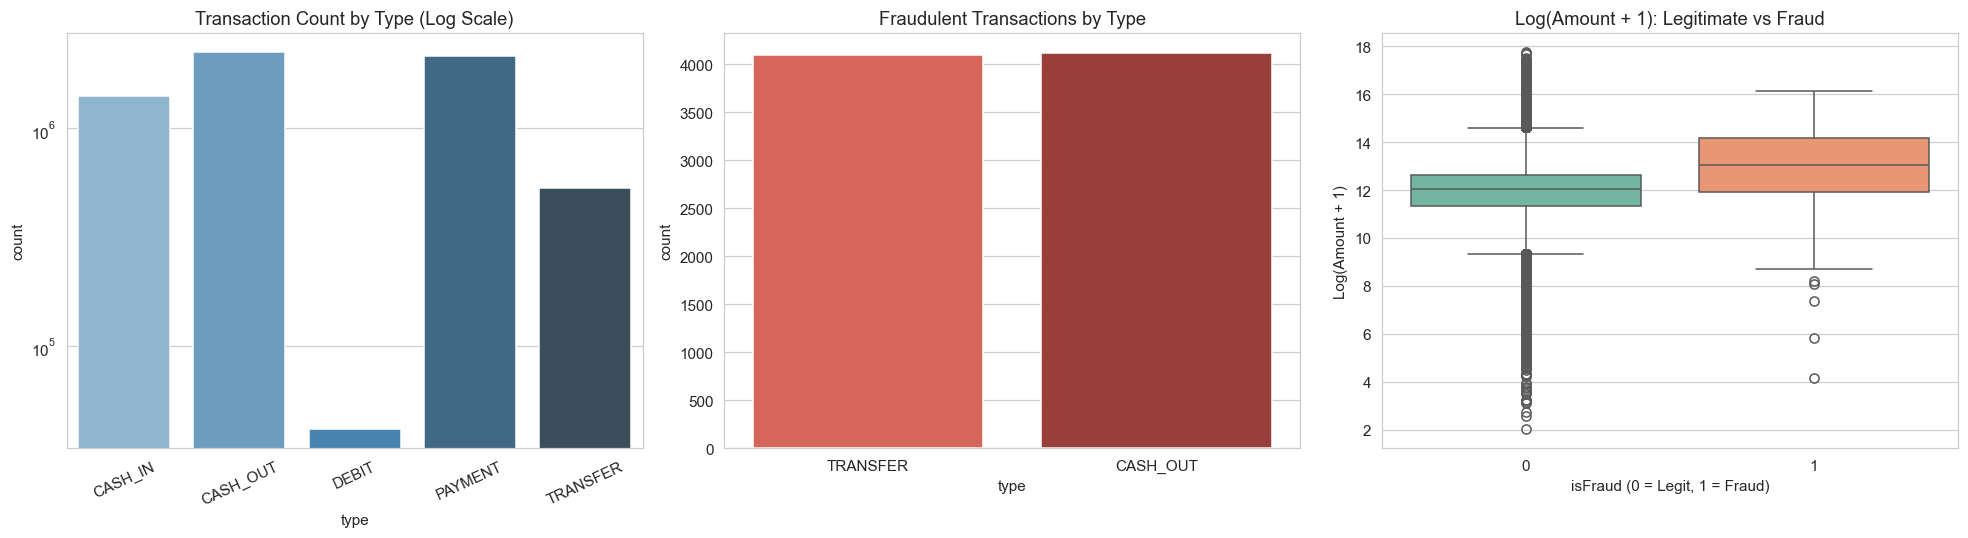

In [6]:
# Visual EDA: Transaction Volume, Fraud Count, and Transaction Amount Distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Total Transactions by Type (Log Scale)
sns.countplot(data=df, x='type', ax=axes[0], palette='Blues_d')
axes[0].set_yscale('log')
axes[0].set_title('Transaction Count by Type (Log Scale)')
axes[0].tick_params(axis='x', rotation=25)

# Plot 2: Fraud Count by Type
fraud_only = df[df['isFraud'] == 1]
sns.countplot(data=fraud_only, x='type', order=['TRANSFER', 'CASH_OUT'], ax=axes[1], palette='Reds_d')
axes[1].set_title('Fraudulent Transactions by Type')

# Plot 3: Log Amount Distribution (Fraud vs Legitimate in TRANSFER/CASH_OUT)
subset_plot = df[df['type'].isin(['TRANSFER', 'CASH_OUT'])].sample(n=100000, random_state=42)
sns.boxplot(data=subset_plot, x='isFraud', y=np.log1p(subset_plot['amount']), ax=axes[2], palette='Set2')
axes[2].set_title('Log(Amount + 1): Legitimate vs Fraud')
axes[2].set_xlabel('isFraud (0 = Legit, 1 = Fraud)')
axes[2].set_ylabel('Log(Amount + 1)')

plt.tight_layout()
plt.show()

### EDA Findings:
1. **100% of fraud occurs in `TRANSFER` and `CASH_OUT`**. Filtering to these two categories removes ~3.6M non-fraud rows with zero loss of fraud cases.
2. **Rule-based system (`isFlaggedFraud`) fails badly:** It catches almost none of the actual fraud, proving the need for an ML model.
3. **Fraudulent amounts are significantly larger** and frequently equal the sender's entire balance.
4. **Fraud is not evenly spread over time**, so the chronological validation and test windows contain very different numbers of fraud cases. Metrics on the small validation window are noisy.

## 4. Feature Engineering (Balance-Change & Behavioral Signals)

In [7]:
%%writefile features.py
"""Shared feature engineering for training (notebook) and serving (Streamlit app).

SAFE_FEATURES only use information that exists BEFORE a transaction is approved.
POST_TX_FEATURES use balances after the transaction. In PaySim they leak the label
and would not be available in a real-time decision, so they are NOT used by the model.
"""
import numpy as np
import pandas as pd

SAFE_FEATURES = [
    'is_transfer', 'amount', 'log_amount', 'oldbalanceOrg', 'oldbalanceDest',
    'amount_to_oldOrig_ratio', 'amount_to_oldDest_ratio',
    'amount_ge_old_orig', 'exact_balance_transfer',
    'is_orig_old_zero', 'is_dest_old_zero', 'hour_of_day',
]

POST_TX_FEATURES = [
    'newbalanceOrig', 'newbalanceDest', 'orig_balance_diff', 'dest_balance_diff',
    'errorBalanceOrig', 'errorBalanceDest', 'is_orig_drained', 'is_dest_zero_all',
]


def build_features(data: pd.DataFrame) -> pd.DataFrame:
    """Adds model features. Post-transaction features are added only if those columns exist."""
    d = data.copy()
    # float64 avoids float32 rounding on large amounts (float32 keeps ~7 digits only)
    num_cols = [c for c in ['amount', 'oldbalanceOrg', 'newbalanceOrig',
                            'oldbalanceDest', 'newbalanceDest'] if c in d.columns]
    for c in num_cols:
        d[c] = d[c].astype('float64')

    d['is_transfer'] = (d['type'] == 'TRANSFER').astype('int8')
    d['log_amount'] = np.log1p(d['amount'])
    d['amount_to_oldOrig_ratio'] = d['amount'] / (d['oldbalanceOrg'] + 1.0)
    d['amount_to_oldDest_ratio'] = d['amount'] / (d['oldbalanceDest'] + 1.0)
    d['amount_ge_old_orig'] = ((d['oldbalanceOrg'] > 0) & (d['amount'] >= d['oldbalanceOrg'] - 0.01)).astype('int8')
    d['exact_balance_transfer'] = np.isclose(d['amount'], d['oldbalanceOrg'], atol=1e-2).astype('int8')
    d['is_orig_old_zero'] = (d['oldbalanceOrg'] == 0).astype('int8')
    d['is_dest_old_zero'] = (d['oldbalanceDest'] == 0).astype('int8')
    d['hour_of_day'] = (d['step'] % 24).astype('int8')

    if {'newbalanceOrig', 'newbalanceDest'}.issubset(d.columns):
        d['orig_balance_diff'] = d['oldbalanceOrg'] - d['newbalanceOrig']
        d['dest_balance_diff'] = d['newbalanceDest'] - d['oldbalanceDest']
        d['errorBalanceOrig'] = d['newbalanceOrig'] + d['amount'] - d['oldbalanceOrg']
        d['errorBalanceDest'] = d['oldbalanceDest'] + d['amount'] - d['newbalanceDest']
        d['is_orig_drained'] = ((d['oldbalanceOrg'] > 0) & (d['newbalanceOrig'] == 0)).astype('int8')
        d['is_dest_zero_all'] = ((d['oldbalanceDest'] == 0) & (d['newbalanceDest'] == 0) & (d['amount'] > 0)).astype('int8')
    return d

Overwriting features.py


In [8]:
import importlib, features
importlib.reload(features)
from features import build_features, SAFE_FEATURES, POST_TX_FEATURES

def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    """Keep only the transaction types where fraud occurs, then add features."""
    subset = data[data['type'].isin(['TRANSFER', 'CASH_OUT'])].copy()
    return build_features(subset)

df_clean = engineer_features(df)
del df
gc.collect()

print(f"Filtered Dataset Shape: {df_clean.shape}")
print(f"Fraud Rate after filtering non-fraud types: {df_clean['isFraud'].mean()*100:.4f}%")
print(f"\nModel features ({len(SAFE_FEATURES)}, all known before approval): {SAFE_FEATURES}")

Filtered Dataset Shape: (2770409, 26)
Fraud Rate after filtering non-fraud types: 0.2965%

Model features (12, all known before approval): ['is_transfer', 'amount', 'log_amount', 'oldbalanceOrg', 'oldbalanceDest', 'amount_to_oldOrig_ratio', 'amount_to_oldDest_ratio', 'amount_ge_old_orig', 'exact_balance_transfer', 'is_orig_old_zero', 'is_dest_old_zero', 'hour_of_day']


## 5. Chronological Train / Validation / Test Split
Splitting strictly by time (`step`) prevents future data leakage and reflects real production deployment.

In [9]:
FEATURE_COLS = SAFE_FEATURES          # pre-transaction information only
TARGET_COL = 'isFraud'

# Sort chronologically
df_clean = df_clean.sort_values('step', kind='mergesort').reset_index(drop=True)

n = len(df_clean)
train_idx = int(n * 0.70)
val_idx = int(n * 0.85)

train_df = df_clean.iloc[:train_idx]
val_df = df_clean.iloc[train_idx:val_idx]
test_df = df_clean.iloc[val_idx:]

X_train, y_train = train_df[FEATURE_COLS], train_df[TARGET_COL]
X_val, y_val = val_df[FEATURE_COLS], val_df[TARGET_COL]
X_test, y_test = test_df[FEATURE_COLS], test_df[TARGET_COL]

for name, part in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    print(f"{name:5s}: {len(part):>9,} rows | steps {part['step'].min():>3}-{part['step'].max():>3} | "
          f"Fraud: {part[TARGET_COL].sum():>5,} ({part[TARGET_COL].mean()*100:.3f}%)")

Train: 1,939,286 rows | steps   1-323 | Fraud: 3,633 (0.187%)
Val  :   415,561 rows | steps 323-377 | Fraud:   560 (0.135%)
Test :   415,562 rows | steps 377-743 | Fraud: 4,020 (0.967%)


## 6. Sampling Strategies & Model Comparison (PR-AUC)
We compare three approaches on the exact same chronological validation & test sets:
1. **Model A (Random Undersampling + Random Forest):** Fast downsampled baseline (10:1 Legit-to-Fraud ratio).
2. **Model B (Full Data + LightGBM Unweighted):** Trains on all ~1.9M training rows.
3. **Model C (Full Data + Cost-Sensitive LightGBM):** Uses `scale_pos_weight` to handle extreme class imbalance without discarding legitimate data.

Note: the validation set is used for early stopping, model selection and threshold choice. The test set is touched only for final reporting.

In [10]:
results_summary = []

# --- Model A: Random Undersampling (10:1) + Random Forest ---
fraud_train = train_df[train_df[TARGET_COL] == 1]
legit_train = train_df[train_df[TARGET_COL] == 0].sample(n=len(fraud_train) * 10, random_state=42)
rus_train = pd.concat([fraud_train, legit_train]).sample(frac=1, random_state=42)

rf_rus = RandomForestClassifier(n_estimators=150, max_depth=15, n_jobs=-1, random_state=42)
rf_rus.fit(rus_train[FEATURE_COLS], rus_train[TARGET_COL])

val_probs_rf = rf_rus.predict_proba(X_val)[:, 1]
test_probs_rf = rf_rus.predict_proba(X_test)[:, 1]
results_summary.append({
    'Model': 'Random Forest (Undersampled 10:1)',
    'Val_PR_AUC': average_precision_score(y_val, val_probs_rf),
    'Test_PR_AUC': average_precision_score(y_test, test_probs_rf),
    'Test_ROC_AUC': roc_auc_score(y_test, test_probs_rf)
})

# --- Model B: Full Data LightGBM (Default Weight) ---
lgb_base = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_base.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric='average_precision',
    callbacks=[lgb.early_stopping(50, verbose=False)]
)
val_probs_base = lgb_base.predict_proba(X_val)[:, 1]
test_probs_base = lgb_base.predict_proba(X_test)[:, 1]
results_summary.append({
    'Model': 'LightGBM (Full Data - Unweighted)',
    'Val_PR_AUC': average_precision_score(y_val, val_probs_base),
    'Test_PR_AUC': average_precision_score(y_test, test_probs_base),
    'Test_ROC_AUC': roc_auc_score(y_test, test_probs_base)
})

# --- Model C: Full Data LightGBM (Class-Weighted) ---
lgb_weighted = lgb.LGBMClassifier(
    n_estimators=600,
    learning_rate=0.04,
    num_leaves=63,
    subsample_for_bin=200000,
    scale_pos_weight=10,
    colsample_bytree=0.8,
    subsample=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_weighted.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric='average_precision',
    callbacks=[lgb.early_stopping(50, verbose=False)]
)
val_probs_w = lgb_weighted.predict_proba(X_val)[:, 1]
test_probs_w = lgb_weighted.predict_proba(X_test)[:, 1]
results_summary.append({
    'Model': 'LightGBM (Full Data - Weighted)',
    'Val_PR_AUC': average_precision_score(y_val, val_probs_w),
    'Test_PR_AUC': average_precision_score(y_test, test_probs_w),
    'Test_ROC_AUC': roc_auc_score(y_test, test_probs_w)
})

comparison_df = pd.DataFrame(results_summary).sort_values('Val_PR_AUC', ascending=False)
print("=== Model Comparison (Ranked by Validation PR-AUC) ===")
print(comparison_df.to_string(index=False))

=== Model Comparison (Ranked by Validation PR-AUC) ===
                            Model  Val_PR_AUC  Test_PR_AUC  Test_ROC_AUC
Random Forest (Undersampled 10:1)    1.000000     0.999995      1.000000
LightGBM (Full Data - Unweighted)    0.998364     0.998520      0.998507
  LightGBM (Full Data - Weighted)    0.996410     0.999747      0.999815


Selected Best Model: Random Forest (Undersampled 10:1)
Final Test PR-AUC: 1.0000  (95% CI: 1.0000 - 1.0000)
Random-classifier baseline PR-AUC: 0.0097


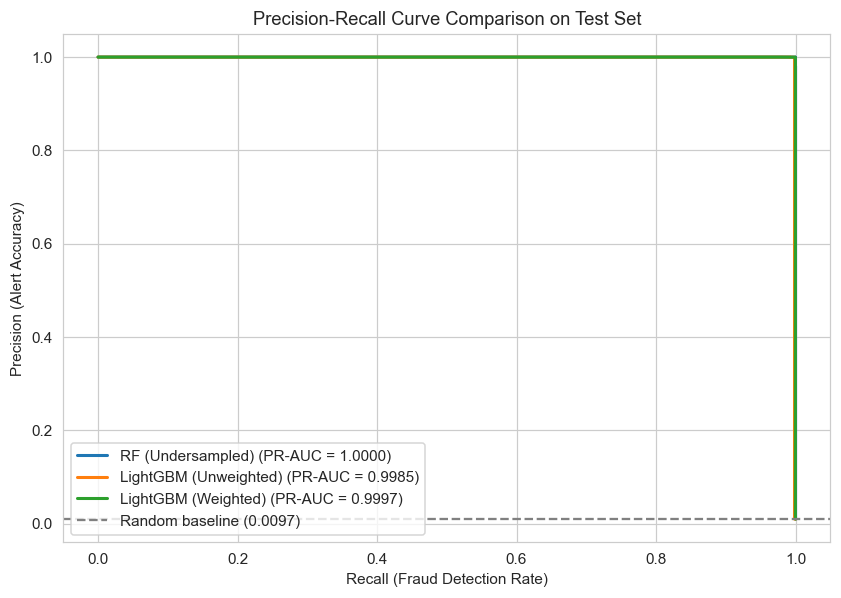

In [11]:
# Select best model based on Validation PR-AUC
best_model_name = comparison_df.iloc[0]['Model']
if 'Weighted' in best_model_name:
    best_model, val_probs, test_probs = lgb_weighted, val_probs_w, test_probs_w
elif 'Unweighted' in best_model_name:
    best_model, val_probs, test_probs = lgb_base, val_probs_base, test_probs_base
else:
    best_model, val_probs, test_probs = rf_rus, val_probs_rf, test_probs_rf

final_test_pr_auc = average_precision_score(y_test, test_probs)

# Bootstrap 95% CI for the test PR-AUC (resampling test transactions)
def bootstrap_pr_auc(y_true, y_score, n_boot=100, seed=42):
    rng = np.random.default_rng(seed)
    y_true, y_score = np.asarray(y_true), np.asarray(y_score)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].sum() == 0:
            continue
        vals.append(average_precision_score(y_true[idx], y_score[idx]))
    return np.percentile(vals, [2.5, 97.5])

ci_low, ci_high = bootstrap_pr_auc(y_test, test_probs)
baseline_pr_auc = float(y_test.mean())   # PR-AUC of a random classifier = fraud prevalence

print(f"Selected Best Model: {best_model_name}")
print(f"Final Test PR-AUC: {final_test_pr_auc:.4f}  (95% CI: {ci_low:.4f} - {ci_high:.4f})")
print(f"Random-classifier baseline PR-AUC: {baseline_pr_auc:.4f}")

# Plot Precision-Recall Curves for all models
plt.figure(figsize=(9, 6))
for label, probs in [
    ('RF (Undersampled)', test_probs_rf),
    ('LightGBM (Unweighted)', test_probs_base),
    ('LightGBM (Weighted)', test_probs_w)
]:
    prec, rec, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)
    plt.plot(rec, prec, linewidth=2, label=f'{label} (PR-AUC = {ap:.4f})')

plt.axhline(baseline_pr_auc, color='gray', linestyle='--', label=f'Random baseline ({baseline_pr_auc:.4f})')
plt.xlabel('Recall (Fraud Detection Rate)')
plt.ylabel('Precision (Alert Accuracy)')
plt.title('Precision-Recall Curve Comparison on Test Set')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

### Leakage ablation: how much did post-transaction features inflate the score?
Same LightGBM, same split. The only difference is whether the post-transaction balance features are included.
A large gap means those features were leaking the label (and are unavailable in real time).

In [12]:
def fit_eval(cols, label):
    m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=42, n_jobs=-1, verbose=-1)
    m.fit(train_df[cols], y_train)
    p = m.predict_proba(test_df[cols])[:, 1]
    return {'Feature set': label, 'n_features': len(cols), 'Test_PR_AUC': average_precision_score(y_test, p)}

ablation_df = pd.DataFrame([
    fit_eval(SAFE_FEATURES, 'Pre-transaction only (used)'),
    fit_eval(SAFE_FEATURES + POST_TX_FEATURES, 'Pre + post-transaction (leaky)'),
])
print(ablation_df.to_string(index=False))

                   Feature set  n_features  Test_PR_AUC
   Pre-transaction only (used)          12     0.120036
Pre + post-transaction (leaky)          20     0.288681


## 7. Stretch Goal: Cost Matrix & Robust Threshold Tuning
Let's define a FinTech Cost Matrix:
| Actual \\ Predicted | Predicted Legitimate (`0`) | Predicted Fraud (`1`) |
|---|---|---|
| **Actual Legitimate (`0`)** | `$0` (True Negative) | `COST_FP` (False Alarm: blocking/reviewing an honest user, e.g., `$15`) |
| **Actual Fraud (`1`)** | `COST_FN` (Missed Fraud loss, e.g., `$500`, or the real transaction amount) | `$0` (True Positive: fraud prevented) |

Choosing the threshold:
- We sweep thresholds on the **Validation Set**. Because validation has few fraud cases, the single cheapest threshold can be a fluke (many thresholds tie).
- So we pick the **middle of the contiguous plateau of thresholds whose cost is within one missed fraud of the minimum**. This is stable and easy to explain.
- Final impact is measured once on the **Test Set**. If the tuned threshold is worse than the default, we report that honestly.

Cheapest single threshold on validation: 0.94 (cost $0.00)
Near-optimal plateau (within one missed fraud): 0.40 - 0.98
Chosen robust threshold (plateau midpoint):    0.69


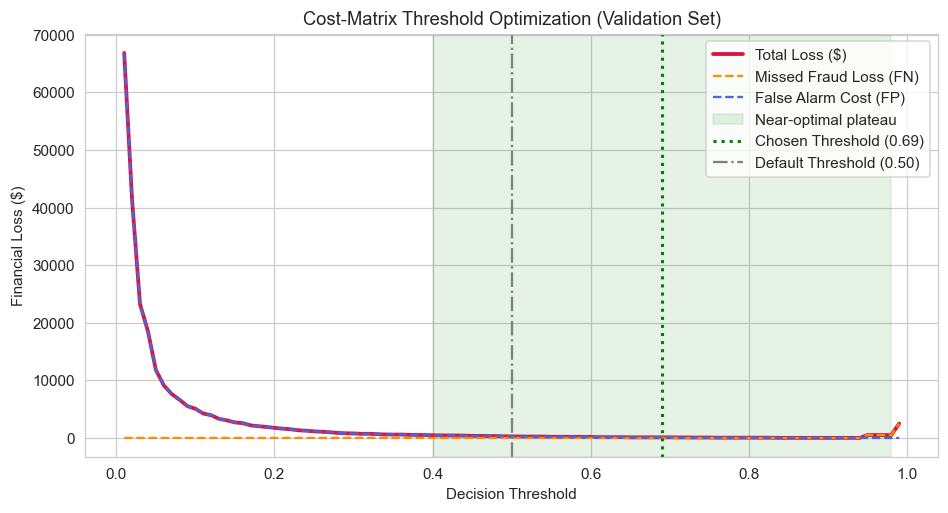

In [13]:
# Default Business Cost Assumptions (editable in the Streamlit UI as well)
COST_FP = 15.0    # Cost of blocking/verifying a legitimate customer ($15)
COST_FN = 500.0   # Average financial loss of an undetected fraudulent transaction ($500)

def compute_threshold_costs(y_true, y_probs, cost_fp=15.0, cost_fn=500.0, amounts=None, dynamic_fn=False):
    """Sweeps thresholds from 0.01 to 0.99 and computes FP, FN, and total financial cost."""
    thresholds = np.linspace(0.01, 0.99, 99)
    y_arr = np.asarray(y_true)
    amt_arr = np.asarray(amounts) if amounts is not None else None
    rows = []
    for t in thresholds:
        preds = (y_probs >= t).astype(int)
        fp_mask = (preds == 1) & (y_arr == 0)
        fn_mask = (preds == 0) & (y_arr == 1)
        tp_mask = (preds == 1) & (y_arr == 1)
        fp, fn, tp = int(fp_mask.sum()), int(fn_mask.sum()), int(tp_mask.sum())
        fp_cost = fp * cost_fp
        fn_cost = float(amt_arr[fn_mask].sum()) if (dynamic_fn and amt_arr is not None) else fn * cost_fn
        rows.append({'threshold': round(float(t), 2), 'TP': tp, 'FP': fp, 'FN': fn,
                     'FP_Cost': fp_cost, 'FN_Cost': fn_cost, 'Total_Cost': fp_cost + fn_cost})
    return pd.DataFrame(rows)

def robust_threshold(cost_curve, tolerance):
    """Midpoint of the contiguous run of thresholds with cost <= min cost + tolerance (around the argmin)."""
    cost = cost_curve['Total_Cost'].to_numpy()
    best = int(cost.argmin())
    ok = cost <= cost.min() + tolerance
    lo = hi = best
    while lo > 0 and ok[lo - 1]: lo -= 1
    while hi < len(cost) - 1 and ok[hi + 1]: hi += 1
    return float(cost_curve['threshold'].iloc[(lo + hi) // 2]), float(cost_curve['threshold'].iloc[lo]), float(cost_curve['threshold'].iloc[hi]), float(cost_curve['threshold'].iloc[best])

val_cost_curve = compute_threshold_costs(y_val, val_probs, cost_fp=COST_FP, cost_fn=COST_FN)
OPTIMAL_THRESHOLD, plateau_lo, plateau_hi, argmin_threshold = robust_threshold(val_cost_curve, tolerance=COST_FN)
min_cost = val_cost_curve['Total_Cost'].min()

print(f"Cheapest single threshold on validation: {argmin_threshold:.2f} (cost ${min_cost:,.2f})")
print(f"Near-optimal plateau (within one missed fraud): {plateau_lo:.2f} - {plateau_hi:.2f}")
print(f"Chosen robust threshold (plateau midpoint):    {OPTIMAL_THRESHOLD:.2f}")

plt.figure(figsize=(10, 5))
plt.plot(val_cost_curve['threshold'], val_cost_curve['Total_Cost'], color='crimson', linewidth=2.5, label='Total Loss ($)')
plt.plot(val_cost_curve['threshold'], val_cost_curve['FN_Cost'], color='darkorange', linestyle='--', label='Missed Fraud Loss (FN)')
plt.plot(val_cost_curve['threshold'], val_cost_curve['FP_Cost'], color='royalblue', linestyle='--', label='False Alarm Cost (FP)')
plt.axvspan(plateau_lo, plateau_hi, color='green', alpha=0.10, label='Near-optimal plateau')
plt.axvline(OPTIMAL_THRESHOLD, color='green', linestyle=':', linewidth=2, label=f'Chosen Threshold ({OPTIMAL_THRESHOLD:.2f})')
plt.axvline(0.50, color='gray', linestyle='-.', linewidth=1.5, label='Default Threshold (0.50)')
plt.title('Cost-Matrix Threshold Optimization (Validation Set)')
plt.xlabel('Decision Threshold')
plt.ylabel('Financial Loss ($)')
plt.legend()
plt.grid(True)
plt.show()

In [14]:
# Evaluate Financial Impact on the Unseen Test Set
test_amounts = test_df['amount'].to_numpy()

def print_test_report(threshold, label):
    preds = (test_probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds, labels=[0, 1]).ravel()
    total_loss = (fp * COST_FP) + (fn * COST_FN)
    amount_loss = fp * COST_FP + float(test_amounts[(preds == 0) & (y_test.to_numpy() == 1)].sum())
    prec = precision_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds, zero_division=0)
    print(f"--- {label} (Threshold = {threshold:.2f}) ---")
    print(f"TP (Fraud Caught): {tp:,} | FN (Fraud Missed): {fn:,} | FP (Honest Blocked): {fp:,}")
    print(f"Precision: {prec:.4f} | Recall: {rec:.4f}")
    print(f"Test loss (fixed ${COST_FN:,.0f} per missed fraud): ${total_loss:,.2f}")
    print(f"Test loss (missed fraud costs its real amount):  ${amount_loss:,.2f}\n")
    return total_loss

loss_default = print_test_report(0.50, "Default Threshold")
loss_optimal = print_test_report(OPTIMAL_THRESHOLD, "Chosen Robust Threshold")

diff = loss_default - loss_optimal
if abs(diff) < 1e-9:
    print("Tuning made no difference versus the default 0.50 threshold on the test set.")
elif diff > 0:
    print(f"Tuning REDUCED test loss by ${diff:,.2f} versus the default 0.50 threshold.")
else:
    print(f"Tuning INCREASED test loss by ${-diff:,.2f} versus the default 0.50 threshold. "
          "The validation optimum did not transfer; report this honestly.")

--- Default Threshold (Threshold = 0.50) ---
TP (Fraud Caught): 4,019 | FN (Fraud Missed): 1 | FP (Honest Blocked): 10
Precision: 0.9975 | Recall: 0.9998
Test loss (fixed $500 per missed fraud): $650.00
Test loss (missed fraud costs its real amount):  $399,195.09

--- Chosen Robust Threshold (Threshold = 0.69) ---
TP (Fraud Caught): 4,019 | FN (Fraud Missed): 1 | FP (Honest Blocked): 2
Precision: 0.9995 | Recall: 0.9998
Test loss (fixed $500 per missed fraud): $530.00
Test loss (missed fraud costs its real amount):  $399,075.09

Tuning REDUCED test loss by $120.00 versus the default 0.50 threshold.


## 8. Export Model Artifacts & Generate Complete Streamlit Web App (`app.py`)
Running the two cells below saves:
1. `artifacts/fraud_model_bundle.joblib` (trained model + feature columns + optimal threshold)
2. `artifacts/sample_transactions.csv` (500 real test transactions for testing CSV upload)
3. `app.py` — the complete required Streamlit application with:
   - **Single Transaction Form** -> instant fraud risk score & decision
   - **Batch CSV Upload** -> fraud score per transaction + downloadable scored CSV
   - **Interactive Threshold Slider & Cost Matrix Controls** -> live Missed Fraud (`FN`) vs. False Alarms (`FP`) and total financial cost breakdown

In [15]:
os.makedirs('artifacts', exist_ok=True)

bundle = {
    'model': best_model,
    'model_name': best_model_name,
    'feature_cols': FEATURE_COLS,
    'optimal_threshold': OPTIMAL_THRESHOLD,
    'default_cost_fp': COST_FP,
    'default_cost_fn': COST_FN,
    'test_pr_auc': float(final_test_pr_auc),
    'test_pr_auc_ci': (float(ci_low), float(ci_high)),
}
joblib.dump(bundle, 'artifacts/fraud_model_bundle.joblib')

# Save sample CSV (fraud + legitimate rows) for a quick app demo
sample_fraud = test_df[test_df['isFraud'] == 1].sample(n=min(50, int((test_df['isFraud'] == 1).sum())), random_state=42)
sample_legit = test_df[test_df['isFraud'] == 0].sample(n=450, random_state=42)
sample_csv = pd.concat([sample_fraud, sample_legit]).sample(frac=1, random_state=42)
raw_cols = ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
            'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud']
sample_csv[raw_cols].to_csv('artifacts/sample_transactions.csv', index=False)

print("Saved 'artifacts/fraud_model_bundle.joblib' and 'artifacts/sample_transactions.csv'.")
print("Deploy these files together: app.py, features.py, artifacts/, requirements.txt")

Saved 'artifacts/fraud_model_bundle.joblib' and 'artifacts/sample_transactions.csv'.
Deploy these files together: app.py, features.py, artifacts/, requirements.txt


In [16]:
%%writefile app.py
import joblib
import numpy as np
import pandas as pd
import streamlit as st

from features import build_features

st.set_page_config(page_title="Mobile-Wallet Fraud Detection", page_icon="🛡️", layout="wide")

REQUIRED_COLS = ['step', 'type', 'amount', 'oldbalanceOrg', 'oldbalanceDest']

@st.cache_resource
def load_bundle():
    return joblib.load("artifacts/fraud_model_bundle.joblib")

def score(df_input: pd.DataFrame) -> np.ndarray:
    """Fraud probability per row. Only TRANSFER and CASH_OUT can be fraud; other types score 0."""
    scores = np.zeros(len(df_input))
    mask = df_input['type'].isin(['TRANSFER', 'CASH_OUT']).to_numpy()
    if mask.any():
        X = build_features(df_input.loc[mask])[feature_cols]
        scores[mask] = model.predict_proba(X)[:, 1]
    return scores

bundle = load_bundle()
model = bundle['model']
feature_cols = bundle['feature_cols']
opt_thresh = bundle['optimal_threshold']
ci = bundle.get('test_pr_auc_ci')
ci_text = f" (95% CI {ci[0]:.3f}-{ci[1]:.3f})" if ci else ""

st.title("🛡️ Mobile-Wallet Fraud Detection & Cost-Based Threshold Tuner")
st.markdown(f"**Model:** `{bundle['model_name']}` | **Test PR-AUC:** `{bundle['test_pr_auc']:.4f}`{ci_text} | **Chosen Threshold:** `{opt_thresh:.2f}`")
st.caption("The model uses only information available before a transaction is approved (no post-transaction balances).")

# Sidebar: Threshold Slider & Cost Matrix Parameters
st.sidebar.header("⚙️ Decision Threshold & Cost Matrix")
threshold = st.sidebar.slider(
    "Classification Threshold", min_value=0.01, max_value=0.99, value=float(opt_thresh), step=0.01,
    help="Transactions with fraud probability >= threshold are flagged/blocked."
)
cost_fp = st.sidebar.number_input("False Alarm Cost (Blocked Honest User $)", min_value=1.0, value=float(bundle['default_cost_fp']), step=5.0)
cost_fn = st.sidebar.number_input("Missed Fraud Cost ($ per missed fraud)", min_value=10.0, value=float(bundle['default_cost_fn']), step=50.0)

tab1, tab2 = st.tabs(["📄 Single Transaction Scoring", "📂 Batch CSV Upload & Cost Simulator"])

# --- TAB 1: Single Transaction Form ---
with tab1:
    st.subheader("Evaluate a Single Mobile-Wallet Transaction")
    with st.form("tx_form"):
        col1, col2, col3 = st.columns(3)
        with col1:
            tx_type = st.selectbox("Transaction Type", ["TRANSFER", "CASH_OUT", "PAYMENT", "CASH_IN", "DEBIT"])
            step = st.number_input("Time Step (Hour 1-744)", min_value=1, max_value=744, value=250)
        with col2:
            amount = st.number_input("Transaction Amount ($)", min_value=0.0, value=150000.0, step=100.0)
            old_orig = st.number_input("Sender Balance Before ($)", min_value=0.0, value=150000.0, step=100.0)
        with col3:
            old_dest = st.number_input("Recipient Balance Before ($)", min_value=0.0, value=0.0, step=100.0)
        submitted = st.form_submit_button("Calculate Fraud Score")

    if submitted:
        row_df = pd.DataFrame([{'step': step, 'type': tx_type, 'amount': amount,
                                'oldbalanceOrg': old_orig, 'oldbalanceDest': old_dest}])
        fraud_prob = float(score(row_df)[0])
        is_flagged = fraud_prob >= threshold
        c1, c2 = st.columns(2)
        c1.metric("Fraud Probability Score", f"{fraud_prob:.4f}")
        c2.metric("Decision", "🚨 BLOCK / REVIEW (FRAUD)" if is_flagged else "✅ APPROVE (LEGITIMATE)")

# --- TAB 2: Batch CSV Upload & Threshold Cost Analysis ---
with tab2:
    st.subheader("Upload Transactions CSV for Batch Scoring & Cost Impact")
    uploaded_file = st.file_uploader("Upload PaySim-format CSV (or use artifacts/sample_transactions.csv)", type=["csv"])

    if uploaded_file is not None:
        raw_df = pd.read_csv(uploaded_file)
        missing = [c for c in REQUIRED_COLS if c not in raw_df.columns]
        if missing:
            st.error(f"Missing required columns: {missing}")
        else:
            raw_df['fraud_score'] = np.round(score(raw_df), 5)
            raw_df['predicted_fraud'] = (raw_df['fraud_score'] >= threshold).astype(int)
            st.write(f"Scored **{len(raw_df):,}** transactions | Flagged as Fraud: **{raw_df['predicted_fraud'].sum():,}**")

            if 'isFraud' in raw_df.columns:
                y_true = raw_df['isFraud'].values
                y_pred = raw_df['predicted_fraud'].values
                tp = int(((y_pred == 1) & (y_true == 1)).sum())
                fn = int(((y_pred == 0) & (y_true == 1)).sum())
                fp = int(((y_pred == 1) & (y_true == 0)).sum())
                fp_loss, fn_loss = fp * cost_fp, fn * cost_fn
                m1, m2, m3, m4 = st.columns(4)
                m1.metric("Fraud Caught (TP)", f"{tp:,}")
                m2.metric("Missed Fraud (FN)", f"{fn:,}", delta=f"-${fn_loss:,.0f} loss", delta_color="inverse")
                m3.metric("False Alarms (FP)", f"{fp:,}", delta=f"-${fp_loss:,.0f} cost", delta_color="inverse")
                m4.metric("Total Financial Loss", f"${fp_loss + fn_loss:,.2f}")

            show_cols = [c for c in ['type', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'fraud_score', 'predicted_fraud'] if c in raw_df.columns]
            st.dataframe(raw_df[show_cols].head(50), use_container_width=True)
            st.download_button("⬇️ Download Scored Transactions CSV", data=raw_df.to_csv(index=False).encode('utf-8'),
                               file_name="scored_transactions.csv", mime="text/csv")

Writing app.py


## 9. How to Run the Web App Locally
After running all cells above, open your terminal in the project folder and run:
```bash
pip install streamlit lightgbm scikit-learn pandas numpy joblib
python -m streamlit run app.py
```

## 10. Deploy on Streamlit Community Cloud
Push these files to a GitHub repo and select `app.py` when creating the app:
`app.py`, `features.py`, `artifacts/fraud_model_bundle.joblib`, `requirements.txt` (the pip packages above, with the same `lightgbm` / `scikit-learn` versions used for training).